# IRS Exposure Engine: EE, EPE, PFE, EEPE

A swap that is worth nothing today can be worth a lot tomorrow, and if the bank on the other side defaults on that day, the value is lost. Counterparty-risk desks therefore look at the whole range of values a swap book could take in the future. This notebook builds the engine that produces those exposure profiles.

**What it does.** It simulates thousands of future interest-rate scenarios and revalues a book of SOFR swaps with five bank counterparties on each one. The result is the set of exposure profiles a counterparty-risk desk monitors against credit limits.

**Data.** Today's SOFR discount curve, built from FRED SOFR, the U.S. Treasury par curve and an explicit swap-spread term structure, plus three years of Treasury yields (FRED) to calibrate rate volatility.

**Methods.** A Hull–White one-factor model calibrated to the historical term structure of volatility, exact Monte Carlo simulation with analytic swap revaluation, netting by counterparty, and the Basel IMM metrics (EE, EPE, EEPE, PFE at 97.5%).

Two fast-pricing surrogates are tested against the exact engine: a Longstaff–Schwartz regression and a PyTorch neural network.

**Key output.** Exposure profiles and netting benefits per counterparty, PFE against limits with a traffic-light view of limit use, and a comparison of the surrogates' speed and accuracy.

## 1. What a counterparty-risk desk needs from this engine

When a development bank (MDB) trades a swap with a commercial bank, the value of that swap moves with interest rates. If the bank defaults on a day when the swap is worth money **to the MDB**, that value is lost.

Counterparty credit risk is therefore about the **future** positive value of the portfolio with each counterparty:

| Metric | Definition | Used for |
|---|---|---|
| **EE(t)**, expected exposure | $\mathbb{E}[\max(V_t,0)]$ | CVA, average loss if default happens at $t$ |
| **PFE(t)**, potential future exposure | 97.5% quantile of $\max(V_t,0)$ | **Credit limits**: "how bad could it get?" |
| **EPE** | time-average of EE over the first year | IMM exposure-at-default |
| **Effective EE / EEPE** | EE made non-decreasing, then averaged over 1 year | Basel IMM: $\text{EAD}=\alpha\cdot\text{EEPE}$ with $\alpha=1.4$ |
| **ENE(t)**, expected negative exposure | $\mathbb{E}[\min(V_t,0)]$ | DVA / own-credit view |

Exposures are computed per **netting set**. Under an ISDA Master Agreement, all trades with a counterparty net into a single amount, so offsetting swaps reduce risk.

This notebook leaves collateral out, which shows the gross risk a CSA would have to cover.

## 2. The model: Hull–White one factor

The short rate is $r_t = x_t + \varphi(t)$, where $x$ follows an Ornstein–Uhlenbeck process

$$
dx_t = -a\,x_t\,dt + \sigma\,dW_t ,\qquad x_0 = 0,
$$

and the deterministic shift $\varphi(t)$ is chosen so the model reproduces today's discount curve exactly. Zero-coupon bond prices stay analytic (Brigo–Mercurio, G1++):

$$
P(t,T)=\frac{P^M(0,T)}{P^M(0,t)}\exp\Big\{\tfrac12\big[V(t,T)-V(0,T)+V(0,t)\big]-B(t,T)\,x_t\Big\},
\qquad B(t,T)=\frac{1-e^{-a(T-t)}}{a},
$$

$$
V(t,T)=\frac{\sigma^2}{a^2}\Big[T-t+\tfrac{2}{a}e^{-a(T-t)}-\tfrac{1}{2a}e^{-2a(T-t)}-\tfrac{3}{2a}\Big].
$$

So a swap can be revalued **exactly** at any future date from the single number $x_t$. That keeps the simulation fast and gives the surrogate models a perfect target to learn.

**Calibration.** PFE is a risk measure about real-world moves, so $(a,\sigma)$ are fitted to the **historical** volatility of yields at different maturities. In this model the volatility of a $\tau$-year zero rate is $\sigma\,B(\tau)/\tau$, which decays with maturity at a speed set by $a$.

## 3. Setup

In [ ]:
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
# any op MPS lacks falls back to CPU
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")
import torch

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import QuantLib as ql
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
from scipy.optimize import least_squares

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

# --- Simulation settings
# Monte Carlo paths (10,000+ for production-grade tails)
N_PATHS = 5_000
DT = 1 / 12  # monthly time grid
PFE_QUANTILE = 0.975  # Basel / market standard
ALPHA_IMM = 1.4  # Basel IMM multiplier: EAD = alpha × EEPE
SEED = 42

# SOFR OIS minus Treasury par (bp): an explicit, documented swap-spread
# assumption
SWAP_SPREAD_BP = {2: -15, 3: -20, 5: -25, 7: -30, 10: -40, 20: -65, 30: -75}

# The surrogate network is small, so the CPU trains it in under a minute and is
# the most robust choice. Set USE_MPS = True to try the Apple-GPU backend
# instead.
USE_MPS = False
DEVICE = "mps" if USE_MPS and torch.backends.mps.is_available() else "cpu"
# leave cores free for NumPy and the OS
torch.set_num_threads(max(1, (os.cpu_count() or 4) // 2))
print(
    f"QuantLib {ql.__version__} · torch {torch.__version__} on {DEVICE} · run"
    f" on {dt.date.today():%Y-%m-%d}"
)

QuantLib 1.44 · torch 2.14.1+cu130 on cpu · run on 2026-10-19


In [2]:
# --- Caching helper
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE_BANDS = ["#cde2fb", "#86b6ef", "#2a78d6"]
STATUS = {"green": "#1f9d55", "amber": "#d08700", "red": "#d03b3b"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 4. Data and today's SOFR curve

- **Treasury par curve** (U.S. Treasury), bootstrapped into zero rates. Adding the swap-spread term structure gives the SOFR discount curve, a standard construction when swap quotes are not available.
- **SOFR fixing** (FRED), used to accrue the floating leg of swaps that are already running.
- **Three years of Treasury yields** (FRED `DGS*`), used to measure realised volatility by maturity.

In [3]:
TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/"
    "daily-treasury-rates.csv/{year}/all?type=daily_treasury_yield_curve"
    "&field_tdr_date_value={year}&page&_format=csv"
)


def tenor_in_years(c):
    m = re.match(r"^\s*([\d.]+)\s*(Mo|Month|Yr|Year)", c)
    return (
        None
        if not m
        else float(m.group(1)) / (12 if m.group(2).startswith("Mo") else 1)
    )


def fetch_treasury_par():
    year = dt.date.today().year
    raw = pd.read_csv(
        io.StringIO(
            requests.get(
                TREASURY_URL.format(year=year),
                headers=BROWSER_HEADERS,
                timeout=30,
            ).text
        )
    )
    if raw.empty:
        raw = pd.read_csv(
            io.StringIO(
                requests.get(
                    TREASURY_URL.format(year=year - 1),
                    headers=BROWSER_HEADERS,
                    timeout=30,
                ).text
            )
        )
    raw["date"] = pd.to_datetime(raw["Date"], format="%m/%d/%Y")
    cols = {
        c: tenor_in_years(c)
        for c in raw.columns
        if tenor_in_years(c) is not None
    }
    long = raw.melt(
        id_vars="date",
        value_vars=list(cols),
        var_name="column",
        value_name="par_yield",
    )
    long["tenor"] = long["column"].map(cols)
    return long[["date", "tenor", "par_yield"]].dropna()


par_curves = cached("treasury_par_curves", fetch_treasury_par).pivot(
    index="date", columns="tenor", values="par_yield"
)
EVAL_DATE = par_curves.index.max()
par_today = par_curves.loc[EVAL_DATE].dropna()

fred = Fred(api_key=FRED_API_KEY)
VOL_SERIES = {
    "DGS1": 1,
    "DGS2": 2,
    "DGS3": 3,
    "DGS5": 5,
    "DGS7": 7,
    "DGS10": 10,
    "DGS20": 20,
    "DGS30": 30,
}


def fetch_vol_history():
    frames = [
        pd.DataFrame({"date": s.index, "tenor": tenor, "yield": s.values})
        for sid, tenor in VOL_SERIES.items()
        for s in [
            fred.get_series(
                sid, observation_start=EVAL_DATE - pd.Timedelta(days=3 * 365)
            ).dropna()
        ]
    ]
    sofr = fred.get_series(
        "SOFR", observation_start=EVAL_DATE - pd.Timedelta(days=30)
    ).dropna()
    frames.append(
        pd.DataFrame({"date": sofr.index, "tenor": 0.0, "yield": sofr.values})
    )
    return pd.concat(frames, ignore_index=True)


hist = (
    cached("fred_vol_history", fetch_vol_history)
    .pivot(index="date", columns="tenor", values="yield")
    .sort_index()
)
SOFR_TODAY = hist[0.0].dropna().iloc[-1] / 100
yields_hist = hist.drop(columns=0.0).dropna()

# --- Treasury zero curve with QuantLib, then SOFR = Treasury zero + swap
# spread
today = EVAL_DATE.normalize()
ql_today = ql.Date(today.day, today.month, today.year)
ql.Settings.instance().evaluationDate = ql_today
US_GOVT = ql.UnitedStates(ql.UnitedStates.GovernmentBond)
helpers, bond_dc = [], ql.ActualActual(ql.ActualActual.Bond)
for tenor, par_yield in par_today.items():
    y = par_yield / 100
    period = (
        ql.Period(int(round(tenor * 52)), ql.Weeks)
        if tenor < 1
        else ql.Period(int(round(tenor * 12)), ql.Months)
    )
    freq, cpns, px = (
        (ql.Once, [0.0], 100 / (1 + y / 2) ** (2 * tenor))
        if tenor <= 1
        else (ql.Semiannual, [y], 100.0)
    )
    sched = ql.Schedule(
        ql_today,
        US_GOVT.advance(ql_today, period),
        ql.Period(freq),
        US_GOVT,
        ql.Unadjusted,
        ql.Unadjusted,
        ql.DateGeneration.Backward,
        False,
    )
    helpers.append(
        ql.FixedRateBondHelper(
            ql.QuoteHandle(ql.SimpleQuote(px)), 0, 100.0, sched, cpns, bond_dc
        )
    )
ust_curve = ql.PiecewiseConvexMonotoneForward(
    ql_today, helpers, ql.Actual365Fixed()
)
ust_curve.enableExtrapolation()

FINE_T = np.linspace(0, 32, 32 * 365 + 1)
ust_z = np.array(
    [ust_curve.zeroRate(max(t, 1e-4), ql.Continuous).rate() for t in FINE_T]
)
spread_curve = np.interp(
    FINE_T, list(SWAP_SPREAD_BP), np.array(list(SWAP_SPREAD_BP.values())) / 1e4
)
sofr_z = ust_z + spread_curve
LOG_DF = -sofr_z * FINE_T


def P0(t):
    """Today's SOFR discount factor P^M(0, t)."""
    return np.exp(np.interp(t, FINE_T, LOG_DF))


def f0(t, h=1e-4):
    """Today's instantaneous forward rate f^M(0, t)."""
    return -(np.log(P0(t + h)) - np.log(P0(np.maximum(t - h, 0)))) / (
        t + h - np.maximum(t - h, 0)
    )


print(
    f"Evaluation date {today:%Y-%m-%d} · SOFR fixing {SOFR_TODAY*100:.2f}% ·"
    f" SOFR zero 2Y {np.interp(2, FINE_T, sofr_z)*100:.2f}% / 10Y"
    f" {np.interp(10, FINE_T, sofr_z)*100:.2f}%"
)

Evaluation date 2026-10-16 · SOFR fixing 3.88% · SOFR zero 2Y 4.54% / 10Y 4.66%


## 5. Calibrating Hull–White to realised volatility

We measure the annualised volatility of daily changes in yields at each maturity, in basis points, and fit $(a,\sigma)$ so the model curve $\sigma B(\tau)/\tau$ matches it. A small $a$ means shocks persist and long rates are almost as volatile as short ones. A large $a$ means long rates barely move.

Calibrated Hull–White: a = 0.0047, sigma = 86.7 bp/yr  (fit RMSE 8.7 bp)


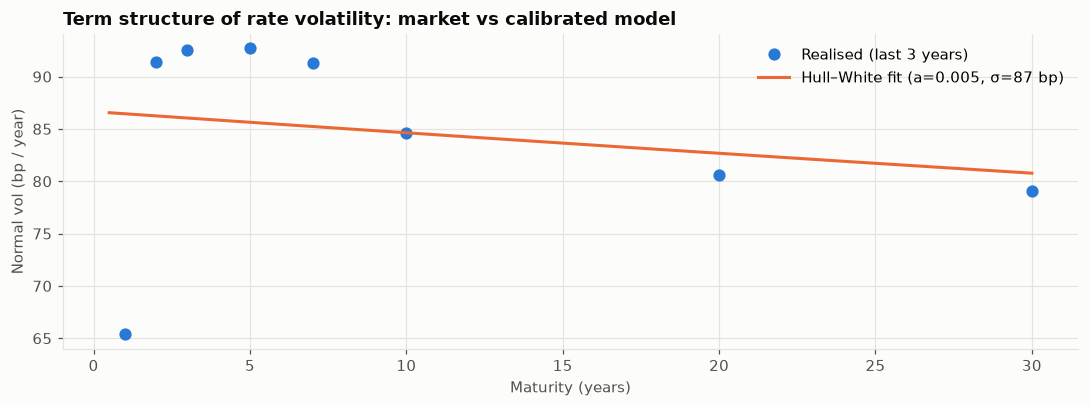

In [4]:
# bp per year, by tenor
realised_vol_bp = yields_hist.diff().dropna().std() * np.sqrt(252) * 100
tenors = realised_vol_bp.index.to_numpy(dtype=float)


def model_vol_bp(params, tau):
    a, sigma = params
    return sigma * (1 - np.exp(-a * tau)) / (a * tau) * 1e4


fit = least_squares(
    lambda p: model_vol_bp(p, tenors) - realised_vol_bp.values,
    x0=[0.05, 0.01],
    bounds=([1e-3, 1e-4], [1.0, 0.05]),
)
A_HW, SIGMA_HW = fit.x
print(
    f"Calibrated Hull–White: a = {A_HW:.4f}, sigma = {SIGMA_HW*1e4:.1f} bp/yr "
    f" (fit RMSE {np.sqrt(np.mean(fit.fun**2)):.1f} bp)"
)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(
    tenors,
    realised_vol_bp.values,
    "o",
    color=PALETTE[0],
    ms=7,
    label="Realised (last 3 years)",
)
tau_grid = np.linspace(0.5, 30, 200)
ax.plot(
    tau_grid,
    model_vol_bp(fit.x, tau_grid),
    color=PALETTE[1],
    label=f"Hull–White fit (a={A_HW:.3f}, σ={SIGMA_HW*1e4:.0f} bp)",
)
ax.set_title("Term structure of rate volatility: market vs calibrated model")
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Normal vol (bp / year)")
ax.legend()
plt.tight_layout()
save_fig(fig, "01_hw_calibration")
plt.show()

## 6. The swap book

Twenty-five SOFR swaps with five bank counterparties, a mix of new and seasoned trades, payer and receiver, from 2 to 30 years. It is synthetic because real trade books are confidential, but every rate is set from today's curve: new trades at par, seasoned trades at the par rate plus a random amount, so they carry realistic mark-to-market.

Each swap pays fixed annually against compounded SOFR. Payment dates fall on the monthly simulation grid, so cash flows drop out of the exposure exactly when they are paid.

In [5]:
rng = np.random.default_rng(SEED)
COUNTERPARTIES = ["Bank A", "Bank B", "Bank C", "Bank D", "Bank E"]


def par_rate(first_pay, n):
    """Par fixed rate today for annual payments at first_pay, first_pay+1, ...
    The current period may have started in the past: that part accrues at
    today's SOFR fixing,
    exactly as the floating leg is valued in the simulation, so a new trade
    starts at zero value.
    """
    pay = first_pay + np.arange(n)
    start = first_pay - 1
    float_leg = (
        np.exp(SOFR_TODAY * (-start)) - P0(pay[-1])
        if start < 0
        else P0(start) - P0(pay[-1])
    )
    return float_leg / P0(pay).sum()


trades = []
for i in range(25):
    # next payment in 1–12 months (month-aligned)
    first_pay = rng.integers(1, 13) / 12
    n_pay = int(rng.choice([2, 3, 5, 7, 10, 10, 15, 20, 30]))
    seasoned = rng.random() < 0.6
    k_par = par_rate(first_pay, n_pay)
    fixed = k_par + (rng.normal(0, 0.0075) if seasoned else 0.0)
    trades.append({
        "trade_id": f"IRS-{i+1:03d}",
        "counterparty": COUNTERPARTIES[i % 5],
        "direction": rng.choice(["receive fixed", "pay fixed"]),
        "notional_mm": float(rng.choice([25, 50, 100, 150, 250, 400])),
        "first_pay": first_pay,
        "n_pay": n_pay,
        "fixed_rate": fixed,
        "par_rate": k_par,
        "maturity_y": first_pay + n_pay - 1,
    })
book = pd.DataFrame(trades)
book["omega"] = np.where(book["direction"] == "receive fixed", 1.0, -1.0)
book[[
    "trade_id",
    "counterparty",
    "direction",
    "notional_mm",
    "maturity_y",
    "fixed_rate",
    "par_rate",
]].assign(
    fixed_rate=lambda d: d["fixed_rate"] * 100,
    par_rate=lambda d: d["par_rate"] * 100,
).round(
    3
)

,trade_id,counterparty,direction,notional_mm,maturity_y,fixed_rate,par_rate
0,IRS-001,Bank A,receive fixed,250.00,14.17,5.39,4.83
1,IRS-002,Bank B,pay fixed,250.00,1.25,4.25,4.25
2,IRS-003,Bank C,pay fixed,100.00,19.75,4.31,4.95
3,IRS-004,Bank D,receive fixed,250.00,29.25,4.81,4.81
4,IRS-005,Bank E,pay fixed,25.00,6.58,4.95,4.67
5,IRS-006,Bank A,receive fixed,250.00,19.92,4.96,4.96
6,IRS-007,Bank B,receive fixed,400.00,6.75,4.70,4.70
7,IRS-008,Bank C,receive fixed,25.00,19.75,5.34,4.95
8,IRS-009,Bank D,pay fixed,250.00,2.58,4.56,4.56
9,IRS-010,Bank E,receive fixed,100.00,29.42,4.20,4.81


## 7. Monte Carlo simulation

The OU factor is simulated exactly, so there is no discretisation error:
$x_{t+\Delta}=x_t e^{-a\Delta}+\sigma\sqrt{\tfrac{1-e^{-2a\Delta}}{2a}}\,Z$.
We also accumulate $\int r_s\,ds$ along each path, which is needed to accrue the SOFR leg of a swap between payment dates.

In [6]:
HORIZON = book["maturity_y"].max()
TIME = np.round(np.arange(0, HORIZON + DT / 2, DT), 10)
N_STEPS = len(TIME)

# --- Simulate x_t (exact OU)
rng_paths = np.random.default_rng(SEED + 1)
x = np.zeros((N_PATHS, N_STEPS))
decay = np.exp(-A_HW * DT)
shock_sd = SIGMA_HW * np.sqrt((1 - np.exp(-2 * A_HW * DT)) / (2 * A_HW))
for j in range(1, N_STEPS):
    x[:, j] = x[:, j - 1] * decay + shock_sd * rng_paths.standard_normal(
        N_PATHS
    )

# --- Short rate r = x + phi, with phi fitting today's curve exactly
phi = f0(TIME) + SIGMA_HW**2 / (2 * A_HW**2) * (1 - np.exp(-A_HW * TIME)) ** 2
short_rate = x + phi
# cumulative integral of r (trapezoid) for SOFR compounding
int_r = np.concatenate(
    [
        np.zeros((N_PATHS, 1)),
        np.cumsum(0.5 * (short_rate[:, 1:] + short_rate[:, :-1]) * DT, axis=1),
    ],
    axis=1,
)


def B(t, T):
    return (1 - np.exp(-A_HW * (T - t))) / A_HW


def V(t, T):
    tau = T - t
    return (
        SIGMA_HW**2
        / A_HW**2
        * (
            tau
            + 2 / A_HW * np.exp(-A_HW * tau)
            - np.exp(-2 * A_HW * tau) / (2 * A_HW)
            - 3 / (2 * A_HW)
        )
    )


def zcb(t, T, x_t):
    """
    P(t,T) for every path (x_t shape: paths) and every maturity in T (shape: m)
    → paths × m.
    """
    T = np.atleast_1d(T)
    log_a = np.log(P0(T) / P0(t)) + 0.5 * (V(t, T) - V(0.0, T) + V(0.0, t))
    return np.exp(log_a[None, :] - np.outer(x_t, B(t, T)))


# Sanity check: the simulation must reprice today's curve (E[discount factor] =
# P0)
check_T = [1, 5, 10, 20]
mc_df = [np.mean(np.exp(-int_r[:, int(round(T / DT))])) for T in check_T]
print(
    "Martingale check, MC vs curve discount factors: "
    + ", ".join(f"{T}Y {m:.4f} vs {P0(T):.4f}" for T, m in zip(check_T, mc_df))
)

Martingale check, MC vs curve discount factors: 1Y 0.9588 vs 0.9585, 5Y 0.7961 vs 0.7950, 10Y 0.6299 vs 0.6275, 20Y 0.3791 vs 0.3752


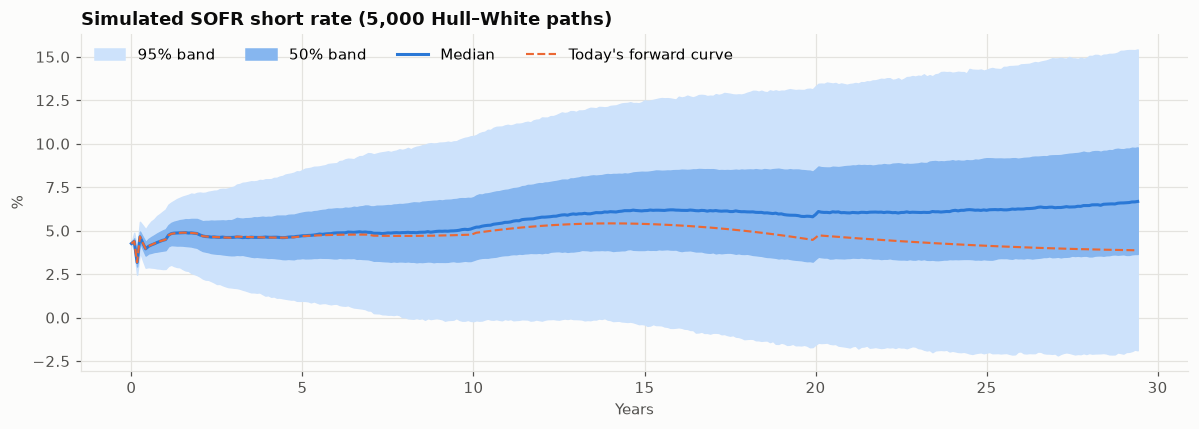

In [7]:
# --- Chart 2: fan chart of the simulated short rate
pct = np.percentile(short_rate * 100, [2.5, 25, 50, 75, 97.5], axis=0)
fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(TIME, pct[0], pct[4], color=BLUE_BANDS[0], label="95% band")
ax.fill_between(TIME, pct[1], pct[3], color=BLUE_BANDS[1], label="50% band")
ax.plot(TIME, pct[2], color=BLUE_BANDS[2], label="Median")
ax.plot(
    TIME,
    f0(TIME) * 100,
    color=PALETTE[1],
    lw=1.4,
    ls="--",
    label="Today's forward curve",
)
ax.set_title(f"Simulated SOFR short rate ({N_PATHS:,} Hull–White paths)")
ax.set_xlabel("Years")
ax.set_ylabel("%")
ax.legend(ncol=4, loc="upper left")
plt.tight_layout()
save_fig(fig, "02_short_rate_fan")
plt.show()

## 8. Revaluing every swap on every path

At each date $t$, for a swap with remaining payment dates $T_i>t$ and the current accrual period starting at $T_{\text{prev}}$:

$$
V^{\text{fix}}_t = K\sum_{i} P(t,T_i), \qquad
V^{\text{float}}_t = \underbrace{e^{\int_{T_{\text{prev}}}^{t} r_s ds}}_{\text{SOFR accrued so far}} - P(t,T_n),
$$

(the coupon being accrued is worth what has compounded so far minus $P(t,T_{\text{next}})$, because the compounding still to come is worth exactly 1; the remaining coupons telescope), and the swap's value to us is $\omega\,(V^{\text{fix}}-V^{\text{float}})\times\text{notional}$, with $\omega=+1$ when receiving fixed. For seasoned trades, the part of the current period that is already past is accrued at today's SOFR fixing.

In [8]:
t0 = time.perf_counter()
# trade × path × date, USD mm
values = np.zeros((len(book), N_PATHS, N_STEPS), dtype=np.float32)

for i, tr in book.iterrows():
    pay = tr["first_pay"] + np.arange(tr["n_pay"])
    prev = pay - 1.0
    for j, t in enumerate(TIME):
        live = pay > t + 1e-9
        if not live.any():
            # matured: value stays 0
            break
        rem = pay[live]
        # paths × remaining payments
        p = zcb(t, rem, x[:, j])
        fixed_leg = tr["fixed_rate"] * p.sum(axis=1)
        # start of the current accrual period
        start = prev[live][0]
        if start >= 0:
            accrual = np.exp(int_r[:, j] - int_r[:, int(round(start / DT))])
        else:  # seasoned: past part accrued at today's fixing
            accrual = np.exp(SOFR_TODAY * (-start) + int_r[:, j])
        # The running coupon is worth (SOFR accrued so far) − P(t, T_next):
        # compounding still to come is worth 1
        float_leg = accrual - p[:, -1]
        values[i, :, j] = (
            tr["omega"] * (fixed_leg - float_leg) * tr["notional_mm"]
        )
exact_seconds = time.perf_counter() - t0

book["mtm_today_mm"] = values[:, :, 0].mean(axis=1)
print(
    f"Revalued {len(book)} swaps × {N_PATHS:,} paths × {N_STEPS} dates in"
    f" {exact_seconds:.1f}s · book MtM today"
    f" {book['mtm_today_mm'].sum():+.1f}mm"
)

Revalued 25 swaps × 5,000 paths × 354 dates in 2.3s · book MtM today -18.5mm


## 9. Exposure metrics by netting set

Trades are summed by counterparty (the netting set) before the positive part is taken. That order of operations is the whole value of an ISDA netting agreement.

In [9]:
def exposure_metrics(v):
    """
    v: paths × dates (USD mm) → dict of EE, ENE, PFE profiles and Basel
    scalars.
    """
    pos, neg = np.maximum(v, 0), np.minimum(v, 0)
    ee = pos.mean(axis=0)
    one_year = TIME <= 1.0 + 1e-9
    eff_ee = np.maximum.accumulate(ee)
    return {
        "EE": ee,
        "ENE": neg.mean(axis=0),
        "PFE": np.quantile(pos, PFE_QUANTILE, axis=0),
        "EPE": ee[one_year].mean(),
        "EEPE": eff_ee[one_year].mean(),
    }


netted = {
    cp: values[book["counterparty"] == cp].sum(axis=0) for cp in COUNTERPARTIES
}
metrics = {cp: exposure_metrics(v) for cp, v in netted.items()}

# Netting benefit: sum of stand-alone trade EEs vs the netted EE (peak over
# time)
standalone_ee = {
    cp: (
        np.maximum(values[book["counterparty"] == cp], 0)
        .mean(axis=1)
        .sum(axis=0)
    )
    for cp in COUNTERPARTIES
}

# Hypothetical credit limits (USD mm of PFE), as a credit officer would set by
# counterparty rating
PFE_LIMITS = {
    "Bank A": 250,
    "Bank B": 80,
    "Bank C": 150,
    "Bank D": 180,
    "Bank E": 100,
}

summary = pd.DataFrame({
    cp: {
        "trades": int((book["counterparty"] == cp).sum()),
        "MtM today": netted[cp][:, 0].mean(),
        "EPE (1y)": m["EPE"],
        "EEPE (1y)": m["EEPE"],
        "EAD = 1.4×EEPE": ALPHA_IMM * m["EEPE"],
        "peak EE": m["EE"].max(),
        "peak PFE 97.5%": m["PFE"].max(),
        "PFE limit": PFE_LIMITS[cp],
        "netting benefit %": (
            (1 - m["EE"].max() / standalone_ee[cp].max()) * 100
            if standalone_ee[cp].max() > 0
            else 0
        ),
    }
    for cp, m in metrics.items()
}).T
summary["utilisation %"] = (
    summary["peak PFE 97.5%"] / summary["PFE limit"] * 100
)
summary["status"] = pd.cut(
    summary["utilisation %"],
    [-np.inf, 75, 100, np.inf],
    labels=["🟢 within", "🟡 watch", "🔴 breach"],
)
summary.round(1)

,trades,MtM today,EPE (1y),EEPE (1y),EAD = 1.4×EEPE,peak EE,peak PFE 97.5%,PFE limit,netting benefit %,utilisation %,status
Bank A,5.00,14.10,22.00,22.00,30.80,40.10,216.20,250.00,1.10,86.50,🟡 watch
Bank B,5.00,-44.90,0.20,0.20,0.20,4.10,45.00,80.00,87.70,56.30,🟢 within
Bank C,5.00,11.70,12.40,12.80,17.90,18.60,104.20,150.00,54.00,69.50,🟢 within
Bank D,5.00,6.50,6.90,7.30,10.20,26.90,204.90,180.00,36.40,113.80,🔴 breach
Bank E,5.00,-5.80,4.20,4.20,5.90,12.80,82.90,100.00,44.90,82.90,🟡 watch


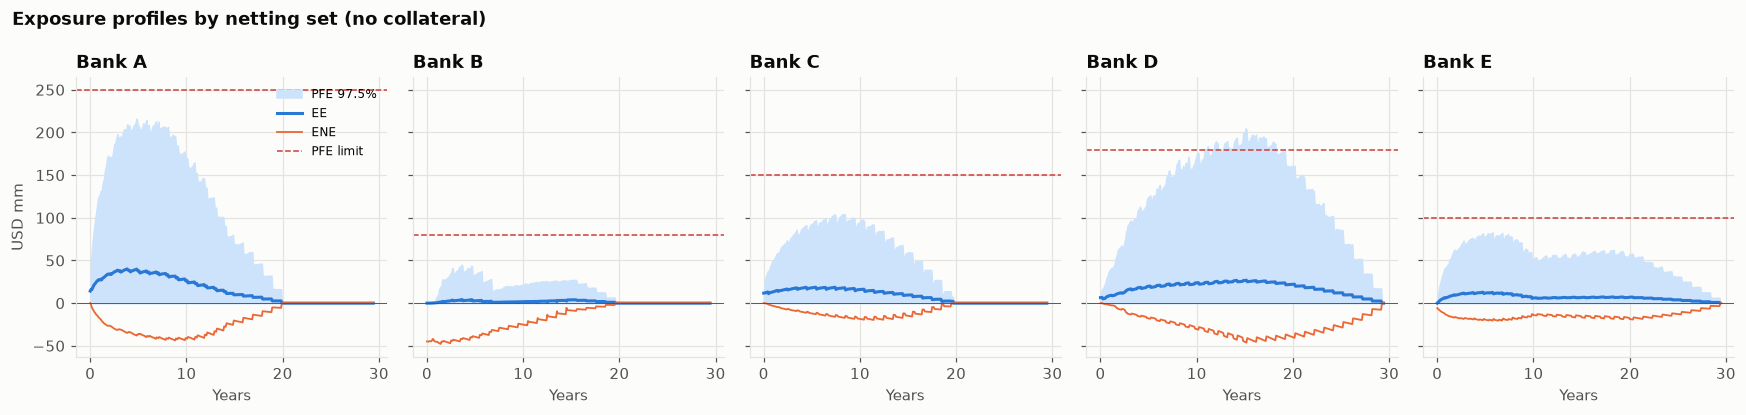

In [10]:
# --- Chart 3: exposure profiles, one small multiple per counterparty
fig, axes = plt.subplots(1, 5, figsize=(16, 3.8), sharey=True)
for ax, cp in zip(axes, COUNTERPARTIES):
    m = metrics[cp]
    ax.fill_between(TIME, 0, m["PFE"], color=BLUE_BANDS[0], label="PFE 97.5%")
    ax.plot(TIME, m["EE"], color=PALETTE[0], label="EE")
    ax.plot(TIME, m["ENE"], color=PALETTE[1], lw=1.2, label="ENE")
    ax.axhline(
        PFE_LIMITS[cp], color=STATUS["red"], lw=1, ls="--", label="PFE limit"
    )
    ax.axhline(0, color=INK_2, lw=0.6)
    ax.set_title(cp)
    ax.set_xlabel("Years")
axes[0].set_ylabel("USD mm")
axes[0].legend(fontsize=8, loc="upper right")
fig.suptitle(
    "Exposure profiles by netting set (no collateral)",
    x=0.01,
    ha="left",
    fontweight="bold",
    color=INK,
)
plt.tight_layout()
save_fig(fig, "03_exposure_profiles")
plt.show()

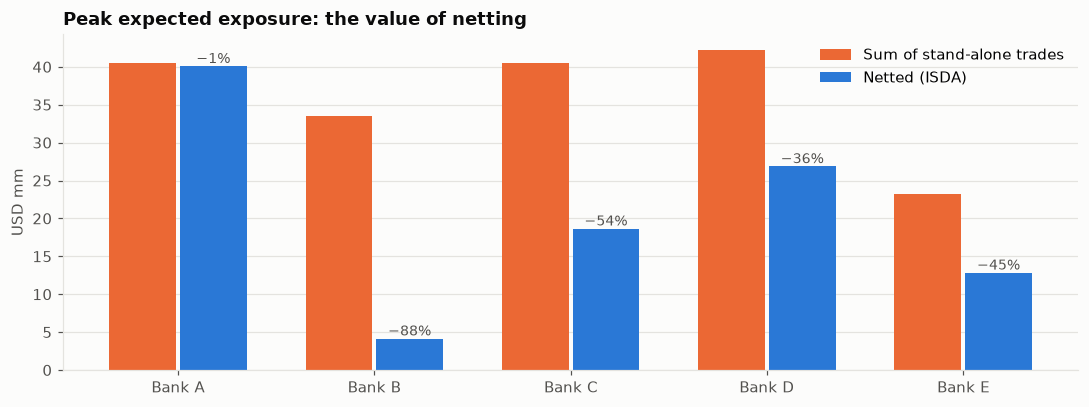

In [11]:
# --- Chart 4: what netting buys, peak EE stand-alone vs netted
fig, ax = plt.subplots(figsize=(10, 3.8))
x_pos = np.arange(len(COUNTERPARTIES))
ax.bar(
    x_pos - 0.18,
    [standalone_ee[c].max() for c in COUNTERPARTIES],
    width=0.34,
    color=PALETTE[1],
    label="Sum of stand-alone trades",
)
ax.bar(
    x_pos + 0.18,
    [metrics[c]["EE"].max() for c in COUNTERPARTIES],
    width=0.34,
    color=PALETTE[0],
    label="Netted (ISDA)",
)
for xp, c in zip(x_pos, COUNTERPARTIES):
    ax.text(
        xp + 0.18,
        metrics[c]["EE"].max(),
        f"−{summary.loc[c, 'netting benefit %']:.0f}%",
        ha="center",
        va="bottom",
        color=INK_2,
        fontsize=9,
    )
ax.set_xticks(x_pos, COUNTERPARTIES)
ax.set_title("Peak expected exposure: the value of netting")
ax.set_ylabel("USD mm")
ax.legend()
ax.grid(axis="x", visible=False)
plt.tight_layout()
save_fig(fig, "04_netting_benefit")
plt.show()

## 10. Fast pricing: regression (LSM) and neural-network surrogates

Exact revaluation is cheap here because Hull–White swaps have closed forms. Most real books contain trades that don't: Bermudan swaptions, callables, cross-currency swaps. Exposure engines then rely on **surrogates**, fast approximations of the trade value as a function of the simulated state:

- **Longstaff–Schwartz (LSM) regression.** At each date, regress the simulated values on a polynomial in the state $x_t$. This is the standard "American Monte Carlo" technique.
- **Neural network.** A small MLP learns the netting-set value across all dates at once, from the state $x_t$ plus term-sheet features (time since each trade's last payment, and whether it is still alive). Here it is trained on half of the paths and tested on the other half, on the Apple GPU when available.

We test both on the largest netting set and compare the exposure profiles they produce with the exact ones.

In [12]:
target_cp = max(COUNTERPARTIES, key=lambda c: metrics[c]["PFE"].max())
v_exact = netted[target_cp]
train_paths = np.arange(N_PATHS) < N_PATHS // 2
test_paths = ~train_paths

# --- LSM: cubic polynomial in x_t, fitted date by date on the training paths
t0 = time.perf_counter()
v_lsm = np.zeros_like(v_exact)
for j in range(N_STEPS):
    # [x³, x², x, 1], scaled for stability
    basis = np.vander(x[:, j] / SIGMA_HW, 4)
    coef, *_ = np.linalg.lstsq(
        basis[train_paths], v_exact[train_paths, j], rcond=None
    )
    v_lsm[:, j] = basis @ coef
lsm_seconds = time.perf_counter() - t0

# --- MLP: V(t, x) learned across all dates
# The netting-set value jumps on every payment date, so (t, x) alone is a hard
# target. We add two features per trade, both known from the term sheet: time
# since its last payment and an "alive" flag. This is the kind of feature
# engineering that makes ML pricers work in practice.
torch.manual_seed(SEED)
cp_trades = book[book["counterparty"] == target_cp]
time_feats = [TIME / HORIZON]
for _, tr in cp_trades.iterrows():
    # fraction of the year since last payment
    time_feats.append(np.mod(TIME - tr["first_pay"], 1.0))
    # trade still alive?
    time_feats.append((TIME < tr["maturity_y"] - 1e-9).astype(float))
# dates × features
time_feats = np.stack(time_feats, axis=-1)
X_all = (
    np.concatenate(
        [
            np.broadcast_to(time_feats[None], (N_PATHS, *time_feats.shape)),
            (x / (3 * SIGMA_HW))[..., None],
        ],
        axis=-1,
    )
    .reshape(-1, time_feats.shape[1] + 1)
    .astype(np.float32)
)
scale_v = np.abs(v_exact).max()
y_all = (v_exact / scale_v).reshape(-1, 1).astype(np.float32)
train_mask = np.broadcast_to(train_paths[:, None], x.shape).reshape(-1)

net = torch.nn.Sequential(
    torch.nn.Linear(X_all.shape[1], 64),
    torch.nn.SiLU(),
    torch.nn.Linear(64, 64),
    torch.nn.SiLU(),
    torch.nn.Linear(64, 64),
    torch.nn.SiLU(),
    torch.nn.Linear(64, 1),
).to(DEVICE)
opt = torch.optim.Adam(net.parameters(), lr=3e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=4000)
X_train = torch.tensor(X_all[train_mask], device=DEVICE)
y_train = torch.tensor(y_all[train_mask], device=DEVICE)

t0 = time.perf_counter()
for step in range(4000):
    idx = torch.randint(0, len(X_train), (8192,), device=DEVICE)
    loss = torch.mean((net(X_train[idx]) - y_train[idx]) ** 2)
    opt.zero_grad()
    loss.backward()
    opt.step()
    sched.step()
train_seconds = time.perf_counter() - t0

t0 = time.perf_counter()
with torch.no_grad():
    v_mlp = (
        net(torch.tensor(X_all, device=DEVICE)).cpu().numpy().reshape(x.shape)
        * scale_v
    )
mlp_seconds = time.perf_counter() - t0
print(
    f"Target netting set: {target_cp} · MLP trained in {train_seconds:.1f}s on"
    f" {DEVICE} (final loss {loss.item():.2e})"
)

Target netting set: Bank A · MLP trained in 42.3s on cpu (final loss 5.28e-06)


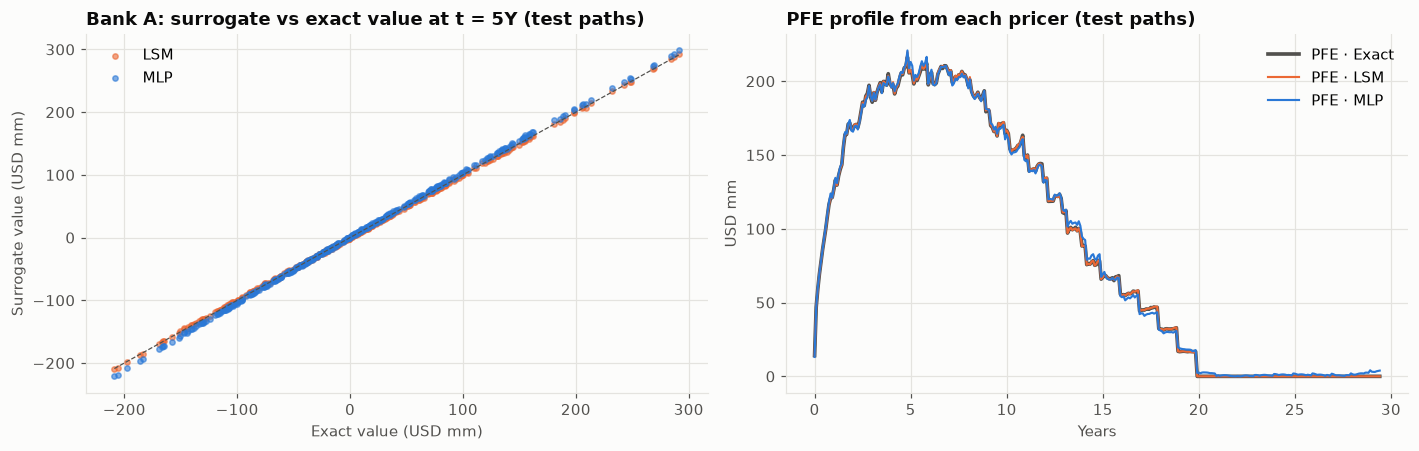

,value RMSE (USD mm),peak EE error %,peak PFE error %,EEPE error %,valuation time (s)
method,,,,,
Exact (closed form),0.00,0.00,0.00,0.00,0.42
LSM cubic regression,0.80,0.01,1.58,0.04,0.12
Neural network (MLP),1.54,-0.50,2.09,-0.23,2.17


In [13]:
def surrogate_report(v_hat, name, seconds):
    m_hat, m_true = exposure_metrics(v_hat[test_paths]), exposure_metrics(
        v_exact[test_paths]
    )
    rmse = np.sqrt(np.mean((v_hat[test_paths] - v_exact[test_paths]) ** 2))
    return {
        "method": name,
        "value RMSE (USD mm)": rmse,
        "peak EE error %": (m_hat["EE"].max() / m_true["EE"].max() - 1) * 100,
        "peak PFE error %": (
            m_hat["PFE"].max() / m_true["PFE"].max() - 1
        ) * 100,
        "EEPE error %": (m_hat["EEPE"] / m_true["EEPE"] - 1) * 100,
        "valuation time (s)": seconds,
    }


notional_cp = book.loc[book["counterparty"] == target_cp, "notional_mm"].sum()
# pro-rata share of exact pricing
exact_cp_seconds = exact_seconds * notional_cp / book["notional_mm"].sum()
surrogates = pd.DataFrame([
    {
        "method": "Exact (closed form)",
        "value RMSE (USD mm)": 0.0,
        "peak EE error %": 0.0,
        "peak PFE error %": 0.0,
        "EEPE error %": 0.0,
        "valuation time (s)": exact_cp_seconds,
    },
    surrogate_report(v_lsm, "LSM cubic regression", lsm_seconds),
    surrogate_report(v_mlp, "Neural network (MLP)", mlp_seconds),
]).set_index("method")

# --- Chart 5: accuracy of the surrogates
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
sample = np.random.default_rng(0).choice(
    np.flatnonzero(test_paths), 400, replace=False
)
j_mid = int(round(min(5, HORIZON / 2) / DT))
ax.scatter(
    v_exact[sample, j_mid],
    v_lsm[sample, j_mid],
    s=12,
    color=PALETTE[1],
    alpha=0.6,
    label="LSM",
)
ax.scatter(
    v_exact[sample, j_mid],
    v_mlp[sample, j_mid],
    s=12,
    color=PALETTE[0],
    alpha=0.6,
    label="MLP",
)
lim = [v_exact[sample, j_mid].min(), v_exact[sample, j_mid].max()]
ax.plot(lim, lim, color=INK_2, lw=0.8, ls="--")
ax.set_title(
    f"{target_cp}: surrogate vs exact value at t = {TIME[j_mid]:.0f}Y (test"
    " paths)"
)
ax.set_xlabel("Exact value (USD mm)")
ax.set_ylabel("Surrogate value (USD mm)")
ax.legend()

ax = axes[1]
for v_hat, name, color in [
    (v_exact, "Exact", INK_2),
    (v_lsm, "LSM", PALETTE[1]),
    (v_mlp, "MLP", PALETTE[0]),
]:
    m = exposure_metrics(v_hat[test_paths])
    ax.plot(
        TIME,
        m["PFE"],
        color=color,
        lw=2.4 if name == "Exact" else 1.4,
        label=f"PFE · {name}",
    )
ax.set_title("PFE profile from each pricer (test paths)")
ax.set_xlabel("Years")
ax.set_ylabel("USD mm")
ax.legend()
plt.tight_layout()
save_fig(fig, "05_surrogate_accuracy")
plt.show()
surrogates.round(3)

## 11. Counterparty exposure dashboard

In [14]:
status_color = {
    "🟢 within": STATUS["green"],
    "🟡 watch": STATUS["amber"],
    "🔴 breach": STATUS["red"],
}
dash = make_subplots(
    rows=2,
    cols=2,
    vertical_spacing=0.15,
    horizontal_spacing=0.09,
    specs=[[{}, {}], [{"colspan": 2, "type": "table"}, None]],
    subplot_titles=(
        "Peak PFE vs limit (utilisation %)",
        "Expected exposure by netting set (USD mm)",
        "Counterparty scorecard",
    ),
)
dash.add_trace(
    go.Bar(
        x=summary.index,
        y=summary["utilisation %"],
        showlegend=False,
        marker_color=[status_color[s] for s in summary["status"]],
        text=[f"{u:.0f}%" for u in summary["utilisation %"]],
        textposition="outside",
    ),
    1,
    1,
)
dash.add_hline(
    y=100, line=dict(color=STATUS["red"], dash="dash", width=1), row=1, col=1
)
for i, cp in enumerate(COUNTERPARTIES):
    dash.add_trace(
        go.Scatter(
            x=TIME,
            y=metrics[cp]["EE"],
            name=cp,
            line=dict(color=PALETTE[i], width=2),
        ),
        1,
        2,
    )
cols = [
    "trades",
    "MtM today",
    "EPE (1y)",
    "EEPE (1y)",
    "EAD = 1.4×EEPE",
    "peak PFE 97.5%",
    "PFE limit",
    "utilisation %",
    "netting benefit %",
    "status",
]
dash.add_trace(
    go.Table(
        header=dict(
            values=["Counterparty"] + cols,
            fill_color="#f1f0ec",
            font=dict(color=INK, size=11),
            align="left",
        ),
        cells=dict(
            values=[summary.index]
            + [
                (
                    summary[c].round(1)
                    if c != "status"
                    else summary[c].astype(str)
                )
                for c in cols
            ],
            fill_color=SURFACE,
            font=dict(color=INK_2, size=11),
            align="left",
        ),
    ),
    2,
    1,
)
total_ead = summary["EAD = 1.4×EEPE"].sum()
dash.update_layout(
    height=860,
    width=1350,
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    font=dict(color=INK_2),
    legend=dict(orientation="h", y=1.07, x=0.55),
    margin=dict(t=130),
    title=dict(
        x=0.01,
        text=(
            f"<b>IRS counterparty exposure · {EVAL_DATE:%d %b %Y}</b><br><span"
            f" style='font-size:13px;color:{INK_2}'>{len(book)} swaps ·"
            f" {len(COUNTERPARTIES)} netting sets · {N_PATHS:,} Hull–White"
            f" paths (a={A_HW:.3f}, σ={SIGMA_HW*1e4:.0f} bp) · total IMM EAD"
            f" {total_ead:,.0f}mm ·"
            f" {(summary['status'] == '🔴 breach').sum()} limit"
            " breach(es)</span>"
        ),
    ),
)
dash.update_yaxes(title_text="%", row=1, col=1)
dash.update_xaxes(title_text="Years", row=1, col=2)
dash.write_html(OUT_DIR / "dashboard.html", include_plotlyjs="cdn")
try:
    dash.write_image(OUT_DIR / "dashboard.png", scale=2)
    print("Dashboard saved: outputs/dashboard.html and .png")
except Exception as err:
    print(
        f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
        " `plotly_get_chrome` once."
    )
summary.to_csv(OUT_DIR / "counterparty_exposure_summary.csv")
pd.DataFrame({
    "years": TIME,
    **{f"EE_{c}": metrics[c]["EE"] for c in COUNTERPARTIES},
    **{f"PFE_{c}": metrics[c]["PFE"] for c in COUNTERPARTIES},
}).to_csv(OUT_DIR / "exposure_profiles.csv", index=False)
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 12. Reading the results and limitations

**What to look for**

**The hump.** EE and PFE for a single swap rise as rate uncertainty grows, then fall as cash flows are paid and fewer remain. The peak usually sits a third to halfway through the swap's life.

**Netting is often the largest risk mitigant**, before any collateral. A counterparty with offsetting payer and receiver swaps can have a fraction of the gross exposure.

**Limit monitoring uses the peak PFE.** The traffic-light view is the daily output a credit officer signs off. A breach leads either to a CSA or to a stop on new trades with that bank.

**Surrogates.** The cubic LSM regression is nearly exact here, because in a one-factor model swap values are smooth, almost polynomial functions of $x_t$.

The MLP tracks the PFE profile closely without any hand-chosen polynomial basis, but only once it is given term-sheet features (time since last payment, alive flags). Without them its error was several times larger.

The lesson for machine learning in risk is that domain features matter more than network size. The MLP's real advantage shows up with multi-factor models and exotic products, where no simple regression basis exists.

**Limitations**

- **One factor.** All rates move together in Hull–White 1F, so curve twists are under-represented. A two-factor model (G2++) or a PCA-based model captures slope risk.
- **No collateral and no wrong-way risk.** A CSA (thresholds, MTA, margin period of risk) would reduce the exposure, and CVA would need the correlation between credit and rates.
- **Synthetic book.** The engine is generic; a real trade file only needs the same columns as `book`.
- **Swap-spread assumption** for the SOFR curve. In production, the swap spreads would come from reported trades or dealer quotes.

## References

### Finance and regulation

- Basel Committee on Banking Supervision. (2005). *The application of Basel II to trading activities and the treatment of double default effects*. Bank for International Settlements. https://www.bis.org/publ/bcbs116.htm
- Gregory, J. (2020). *The xVA challenge: Counterparty risk, funding, collateral, capital and initial margin* (4th ed.). Wiley. https://doi.org/10.1002/9781119508991
- Hull, J., & White, A. (1990). Pricing interest-rate-derivative securities. *The Review of Financial Studies, 3*(4), 573–592. https://doi.org/10.1093/rfs/3.4.573
- Brigo, D., & Mercurio, F. (2006). *Interest rate models: Theory and practice* (2nd ed.). Springer. https://doi.org/10.1007/978-3-540-34604-3
- Cesari, G., Aquilina, J., Charpillon, N., Filipović, Z., Lee, G., & Manda, I. (2009). *Modelling, pricing, and hedging counterparty credit exposure: A technical guide*. Springer. https://doi.org/10.1007/978-3-642-04454-0

### Machine learning and deep learning

- Longstaff, F. A., & Schwartz, E. S. (2001). Valuing American options by simulation: A simple least-squares approach. *The Review of Financial Studies, 14*(1), 113–147. https://doi.org/10.1093/rfs/14.1.113
- Hornik, K., Stinchcombe, M., & White, H. (1989). Multilayer feedforward networks are universal approximators. *Neural Networks, 2*(5), 359–366. https://doi.org/10.1016/0893-6080(89)90020-8
- Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., … Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems, 32*. https://arxiv.org/abs/1912.01703
- Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. In *Proceedings of the 3rd International Conference on Learning Representations*. https://arxiv.org/abs/1412.6980